# 08 · Evaluación final en el conjunto de prueba (una sola vez)

> **Prototipo académico; no apto para diagnóstico ni decisiones clínicas.**

Todo está decidido antes de abrir la prueba:
- **Modelo:** `resultados/modelo_final.json` (notebook 06).
- **Umbral:** `resultados/umbral_final.json` (notebook 07, elegido con validación).
- Como referencia también se reportan el umbral 0,5 y la línea base del notebook 05 con
  umbral 0,5. Ninguno de estos resultados se usa para cambiar nada.

El notebook deja un **candado** (`resultados/prueba_final/EVALUADA.txt`). Si ya existe, se detiene
para no evaluar la prueba dos veces. Si de verdad hay que repetir (por ejemplo, se cortó Colab
antes de terminar), pon `REPETIR = True` y anótalo en la bitácora con el motivo.

In [1]:
# Montar Drive y fijar rutas (las mismas en todos los notebooks)
from google.colab import drive
drive.mount('/content/drive')

import os, sys
BASE    = "/content/drive/MyDrive/Aprendizaje final"
DATA    = f"{BASE}/Csv"
RES     = f"{BASE}/resultados"
SRC     = f"{BASE}/src"
PART    = f"{RES}/particiones"
PNG     = f"{BASE}/procesadas_224"     # recortes preprocesados (no van a Git)
MODELOS = f"{BASE}/modelos"            # checkpoints .pt (no van a Git)
for p in [DATA, RES, SRC, PART]:
    assert os.path.exists(p), f"No existe: {p}"
sys.path.insert(0, SRC)

Mounted at /content/drive


In [2]:
import json, datetime
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from PIL import Image
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
import modelo_utils as mu

REPETIR = False
PF = f"{RES}/prueba_final"
os.makedirs(PF, exist_ok=True)
CANDADO = f"{PF}/EVALUADA.txt"
if os.path.exists(CANDADO) and not REPETIR:
    raise RuntimeError("La prueba ya se evaluó:\n" + open(CANDADO).read()
                       + "\nSi hay que repetir, pon REPETIR = True y anótalo en la bitácora.")

final = json.load(open(f"{RES}/modelo_final.json"))
umb = json.load(open(f"{RES}/umbral_final.json"))
UMBRAL = umb["umbral"]
print("Modelo:", final["ckpt"], "| umbral:", UMBRAL, "|", umb["criterio"])

Modelo: exp_sin_aumentos_s42.pt | umbral: 0.3 | umbral más alto con sensibilidad de validación >= 0.8


In [3]:
parts = {s: pd.read_csv(f"{PART}/{s}.csv") for s in ["train", "val", "test"]}
test = parts["test"]
for a in ["train", "val"]:
    assert not set(parts[a].patient_id) & set(test.patient_id), f"Pacientes compartidos {a}-test"
assert all(os.path.exists(f"{PNG}/{l}.png") for l in test.lesion_id), "Faltan PNG: ejecuta el notebook 04"
print("Prueba:", len(test), "lesiones,", test.patient_id.nunique(), "pacientes,",
      int(test.label.sum()), "malignas")

dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
dl_test = mu.crear_loader(test, PNG, False, 16, 42)       # sin aumentos

def predecir_ckpt(nombre_modelo, ckpt):
    m = mu.crear_modelo(nombre_modelo)
    m.load_state_dict(torch.load(f"{MODELOS}/{ckpt}", map_location=dispositivo))
    p, _ = mu.predecir(m.to(dispositivo), dl_test, dispositivo)
    return p[["lesion_id", "patient_id", "label", "score"]]

pred_final = predecir_ckpt("resnet18", final["ckpt"])
pred_base = predecir_ckpt("baseline", "baseline.pt")
pred_final.to_csv(f"{PF}/pred_test_final.csv", index=False)
pred_base.to_csv(f"{PF}/pred_test_baseline.csv", index=False)

with open(CANDADO, "w") as f:
    f.write(f"Evaluada el {datetime.datetime.now():%Y-%m-%d %H:%M} con {final['ckpt']} y umbral {UMBRAL}\n")
print(open(CANDADO).read())

Prueba: 28 lesiones, 15 pacientes, 11 malignas
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


Evaluada el 2026-11-21 22:16 con exp_sin_aumentos_s42.pt y umbral 0.3



## Métricas en prueba

In [4]:
filas = []
for nombre, p, u in [("resnet18_final", pred_final, UMBRAL),
                     ("resnet18_final", pred_final, 0.5),
                     ("baseline", pred_base, 0.5)]:
    auc, lo, hi = mu.auc_ic_bootstrap(p)
    filas.append(dict(modelo=nombre, auc=round(auc, 3), auc_ic95=f"{lo:.2f}-{hi:.2f}",
                      **mu.metricas(p.label, p.score, u)))
met = pd.DataFrame(filas).round(3)
met.to_csv(f"{PF}/metricas_prueba.csv", index=False)
met

,modelo,auc,auc_ic95,umbral,TP,FN,TN,FP,sensibilidad,sens_ic95,especificidad,esp_ic95,precision,f1
0,resnet18_final,0.706,0.44-0.97,0.3,5,6,14,3,0.455,0.21-0.72,0.824,0.59-0.94,0.625,0.526
1,resnet18_final,0.706,0.44-0.97,0.5,3,8,16,1,0.273,0.10-0.57,0.941,0.73-0.99,0.750,0.400
2,baseline,0.754,0.53-0.92,0.5,0,11,17,0,0.000,0.00-0.26,1.000,0.82-1.00,NaN,0.000


In [5]:
# Validación frente a prueba, mismo modelo y mismo umbral
pv = pd.read_csv(f"{RES}/pred_val_final.csv")
comp = pd.DataFrame([dict(conjunto=c, auc=round(mu.auc_ic_bootstrap(p)[0], 3),
                          **mu.metricas(p.label, p.score, UMBRAL))
                     for c, p in [("validación", pv), ("prueba", pred_final)]]).round(3)
comp.to_csv(f"{PF}/validacion_vs_prueba.csv", index=False)
comp

,conjunto,auc,umbral,TP,FN,TN,FP,sensibilidad,sens_ic95,especificidad,esp_ic95,precision,f1
0,validación,0.881,0.3,8,2,23,4,0.800,0.49-0.94,0.852,0.68-0.94,0.667,0.727
1,prueba,0.706,0.3,5,6,14,3,0.455,0.21-0.72,0.824,0.59-0.94,0.625,0.526


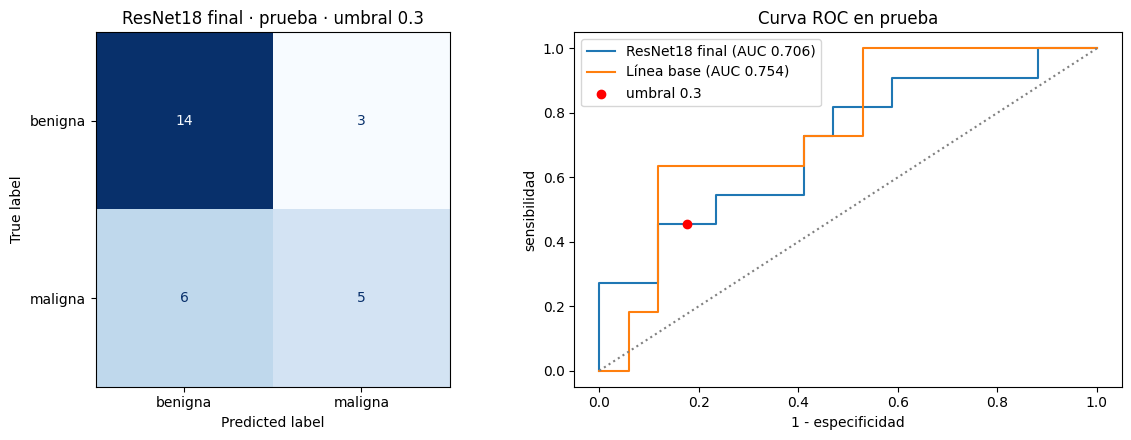

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
p = pred_final.assign(pred=(pred_final.score >= UMBRAL).astype(int))
ConfusionMatrixDisplay.from_predictions(p.label, p.pred, display_labels=["benigna", "maligna"],
                                        cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title(f"ResNet18 final · prueba · umbral {UMBRAL}")
for nombre, pr in [("ResNet18 final", pred_final), ("Línea base", pred_base)]:
    fpr, tpr, _ = roc_curve(pr.label, pr.score)
    ax[1].plot(fpr, tpr, label=f"{nombre} (AUC {mu.auc_ic_bootstrap(pr)[0]:.3f})")
m = mu.metricas(p.label, p.score, UMBRAL)
ax[1].scatter(1 - m["especificidad"], m["sensibilidad"], c="r", zorder=3, label=f"umbral {UMBRAL}")
ax[1].plot([0, 1], [0, 1], ":", c="gray")
ax[1].set_xlabel("1 - especificidad"); ax[1].set_ylabel("sensibilidad")
ax[1].set_title("Curva ROC en prueba"); ax[1].legend()
plt.tight_layout()
plt.savefig(f"{PF}/matriz_y_roc_prueba.png", dpi=110, bbox_inches="tight")
plt.show()

## Errores en prueba

Falsos negativos (6):
          lesion_id patient_id  label    score resultado
 P_00406_RIGHT_CC_1    P_00406      1 0.041509        FN
P_00406_RIGHT_MLO_1    P_00406      1 0.079672        FN
 P_00074_LEFT_MLO_1    P_00074      1 0.137335        FN
 P_00074_RIGHT_CC_1    P_00074      1 0.184007        FN
P_00074_RIGHT_MLO_1    P_00074      1 0.184928        FN
  P_00347_LEFT_CC_1    P_00347      1 0.216516        FN

Falsos positivos (3):
          lesion_id patient_id  label    score resultado
P_00387_RIGHT_MLO_1    P_00387      0 0.619428        FP
 P_00114_LEFT_MLO_1    P_00114      0 0.459151        FP
 P_00027_RIGHT_CC_1    P_00027      0 0.306234        FP


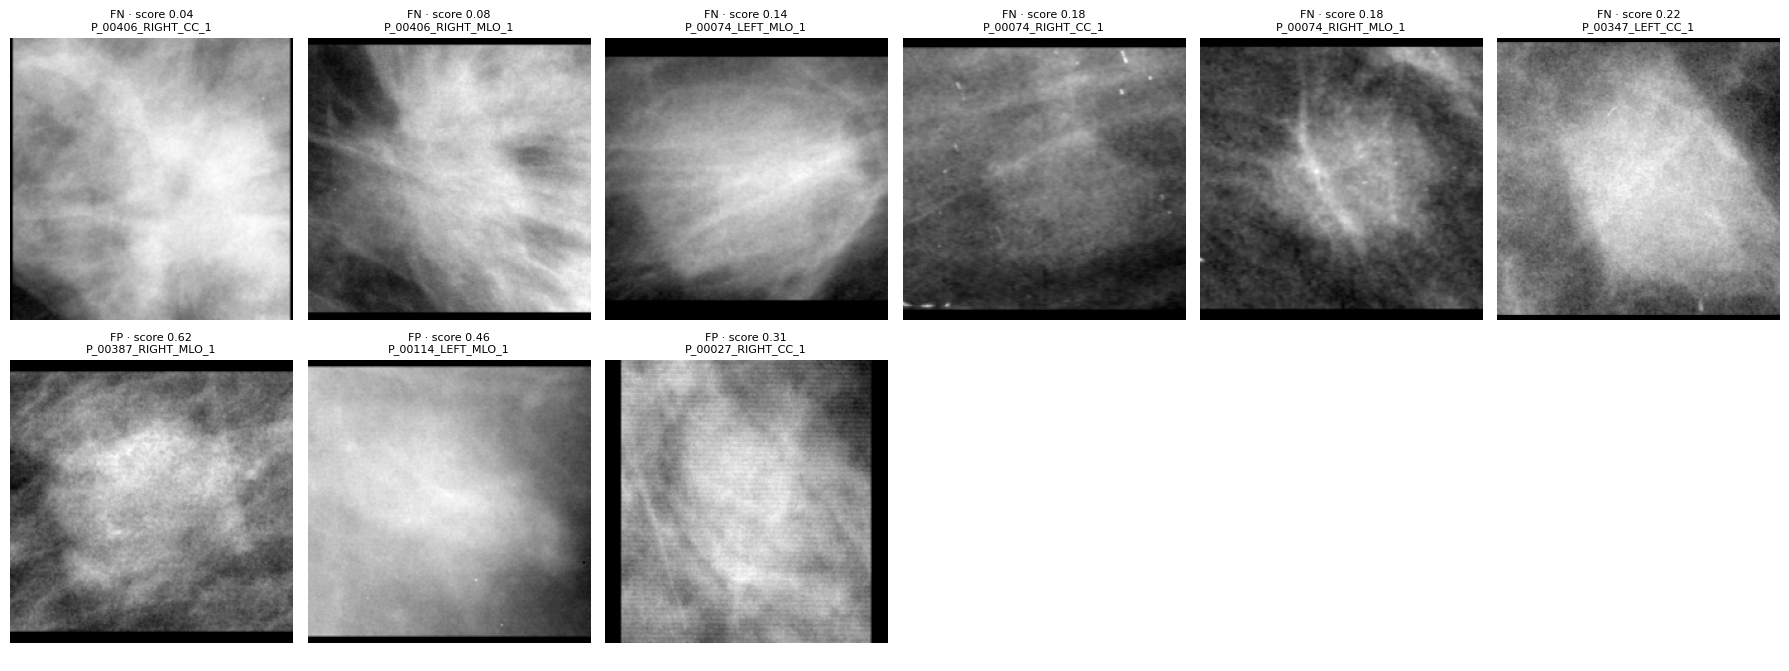

In [7]:
p["resultado"] = np.select([(p.label == 1) & (p.pred == 1), (p.label == 1) & (p.pred == 0),
                            (p.label == 0) & (p.pred == 0)], ["TP", "FN", "TN"], "FP")
fn = p[p.resultado == "FN"].sort_values("score")
fp = p[p.resultado == "FP"].sort_values("score", ascending=False)
print(f"Falsos negativos ({len(fn)}):"); print(fn.drop(columns="pred").to_string(index=False))
print(f"\nFalsos positivos ({len(fp)}):"); print(fp.drop(columns="pred").to_string(index=False))
p.to_csv(f"{PF}/errores_prueba.csv", index=False)

errores = pd.concat([fn, fp])
if len(errores):
    n = len(errores); cols_fig = min(n, 6); filas_fig = int(np.ceil(n / cols_fig))
    fig, ax = plt.subplots(filas_fig, cols_fig, figsize=(3 * cols_fig, 3.4 * filas_fig), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for a, r in zip(ax.ravel(), errores.itertuples()):
        a.imshow(Image.open(f"{PNG}/{r.lesion_id}.png"), cmap="gray")
        a.set_title(f"{r.resultado} · score {r.score:.2f}\n{r.lesion_id}", fontsize=8)
    plt.tight_layout()
    plt.savefig(f"{PF}/errores_prueba.png", dpi=110, bbox_inches="tight")
    plt.show()

## Cómo leer el resultado (sin sobreinterpretar)
- La prueba tiene 28 lesiones (11 malignas). Reporta siempre los **intervalos de confianza**;
  con tan pocos casos son anchos.
- **H1:** compara el AUC de ResNet18 y de la línea base y mira si sus intervalos se solapan.
- **H2:** compara la fila del umbral elegido con la del umbral 0,5.
- **Generalización:** compara validación y prueba con el mismo umbral. Si la prueba sale peor,
  es lo esperable porque el umbral y la época se eligieron con validación.
- Estos números **no se usan para cambiar** el modelo ni el umbral.